In [12]:

import pandas as pd

url = "https://huggingface.co/datasets/jason1966/adityakadiwal_water-potability/resolve/main/water_potability.csv"

df = pd.read_csv(url)

df.head()


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [13]:

df.shape


(3276, 10)

In [14]:

df.isnull().sum()


,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


In [15]:

df = df.fillna(df.median())


In [16]:

df.isnull().sum()


,0
ph,0
Hardness,0
Solids,0
Chloramines,0
Sulfate,0
Conductivity,0
Organic_carbon,0
Trihalomethanes,0
Turbidity,0
Potability,0


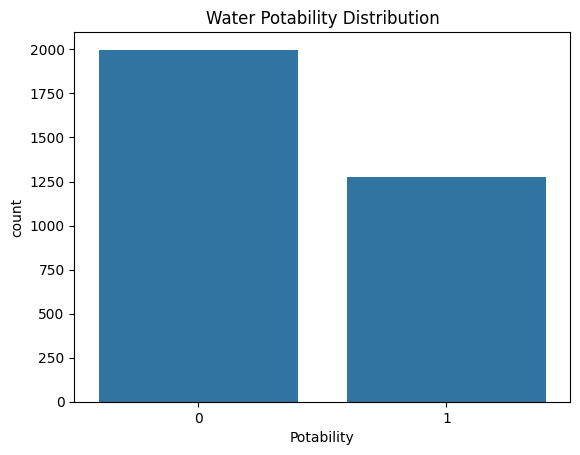

In [17]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Potability')
plt.title('Water Potability Distribution')
plt.show()


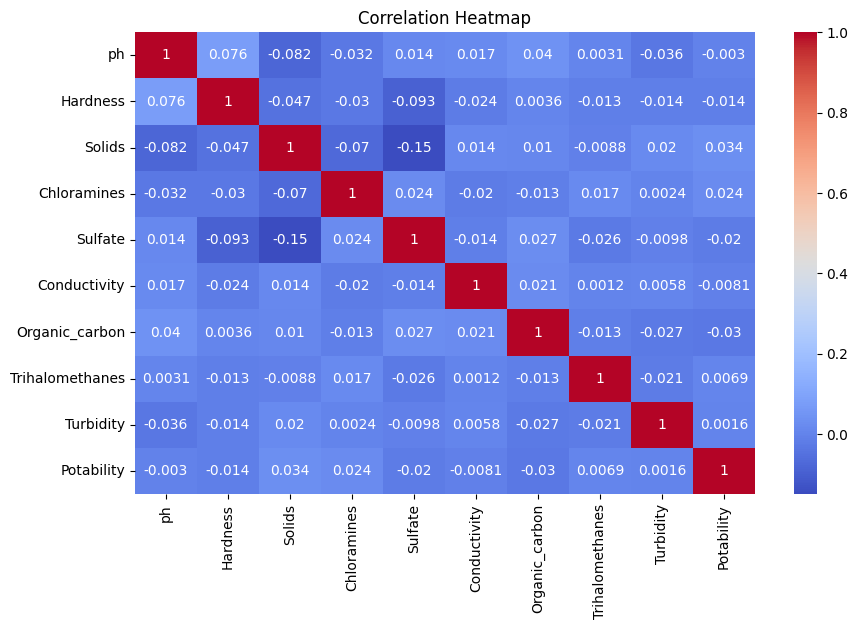

In [18]:

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


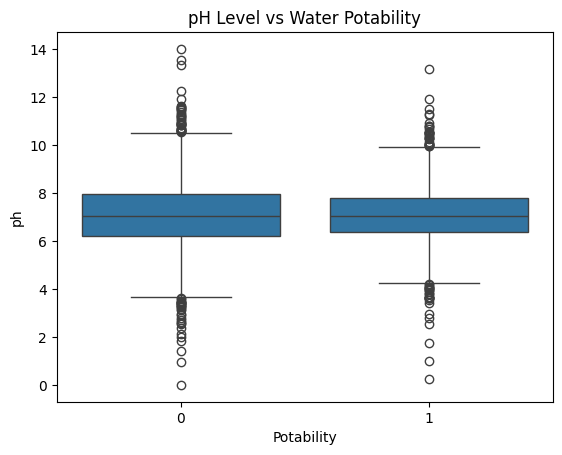

In [19]:

sns.boxplot(data=df, x='Potability', y='ph')
plt.title('pH Level vs Water Potability')
plt.show()


In [20]:

X = df.drop('Potability', axis=1)
y = df['Potability']


In [21]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [22]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [23]:

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=1000)

In [24]:

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [25]:

from sklearn.metrics import accuracy_score

lr_pred = lr.predict(X_test_scaled)
rf_pred = rf.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))


Logistic Regression Accuracy: 0.6097560975609756
Random Forest Accuracy: 0.6585365853658537


In [26]:

from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))


              precision    recall  f1-score   support

           0       0.66      0.89      0.76       400
           1       0.63      0.30      0.41       256

    accuracy                           0.66       656
   macro avg       0.65      0.59      0.58       656
weighted avg       0.65      0.66      0.62       656



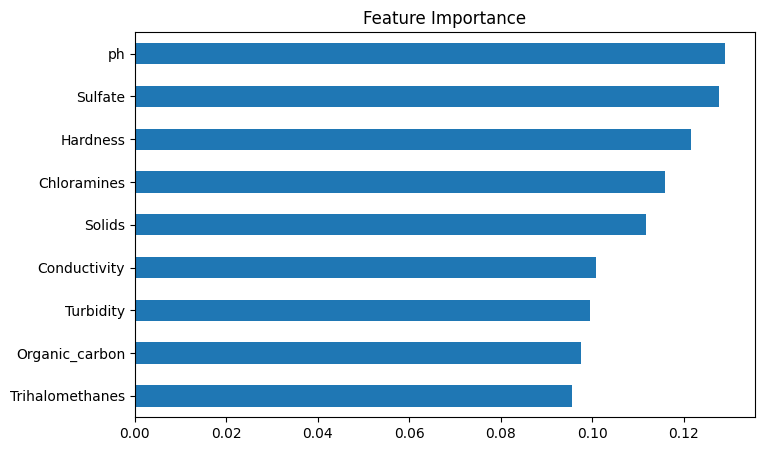

In [27]:

importance = pd.Series(rf.feature_importances_, index=X.columns)

importance.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Feature Importance')
plt.show()


In [28]:

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


df_original = pd.read_csv(url)

X = df_original.drop('Potability', axis=1)
y = df_original['Potability']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fill missing values
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))


Accuracy: 0.6707317073170732
              precision    recall  f1-score   support

           0       0.67      0.91      0.77       400
           1       0.68      0.30      0.41       256

    accuracy                           0.67       656
   macro avg       0.67      0.60      0.59       656
weighted avg       0.67      0.67      0.63       656



In [29]:

import joblib

joblib.dump(rf, 'water_model.pkl')
joblib.dump(imputer, 'imputer.pkl')

print("Model and imputer saved successfully!")


Model and imputer saved successfully!


In [30]:

from google.colab import files

files.download('water_model.pkl')
files.download('imputer.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>